# Linear Regression: What Drives Yearly Customer Spend?

An online clothing retailer sells through both a **mobile app** and a **website**, and offers in-store style sessions.
The business question: *should the company invest more in the mobile app or in the website?*

I fit a multiple linear regression on 500 customers to see which behaviour best explains **Yearly Amount Spent**.

**Tools:** pandas, seaborn, scikit-learn (`LinearRegression`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

## 1. Data

In [2]:
customers = pd.read_csv('data/ecommerce_customers.csv')
customers.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [3]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.3 KB


In [4]:
customers.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## 2. Exploratory analysis

First I compare time spent on the website and on the app against yearly spend.

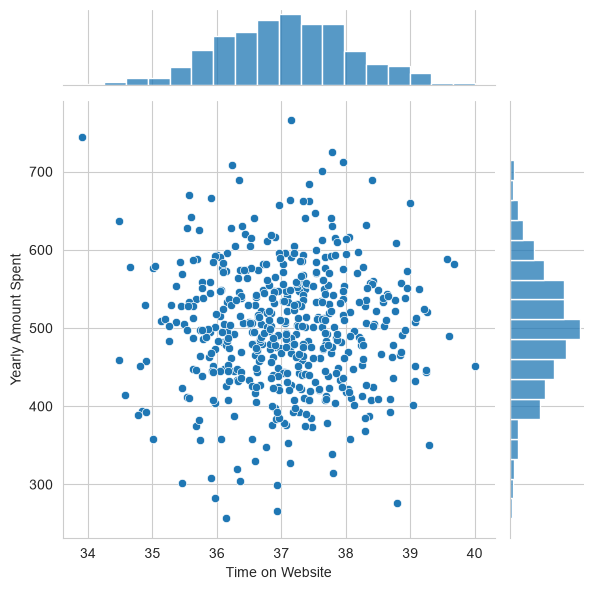

In [5]:
sns.jointplot(data=customers, x='Time on Website', y='Yearly Amount Spent')

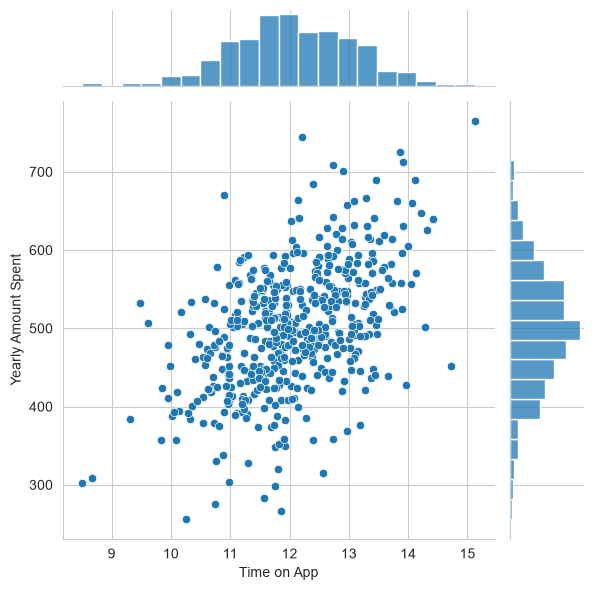

In [6]:
sns.jointplot(data=customers, x='Time on App', y='Yearly Amount Spent')

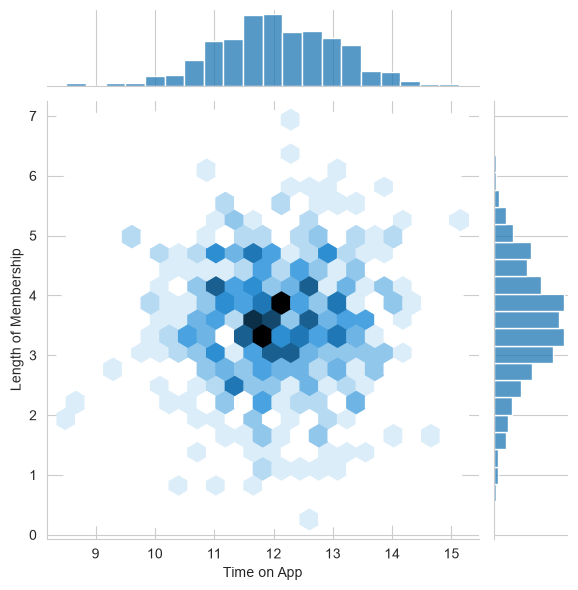

In [7]:
sns.jointplot(data=customers, x='Time on App', y='Length of Membership', kind='hex')

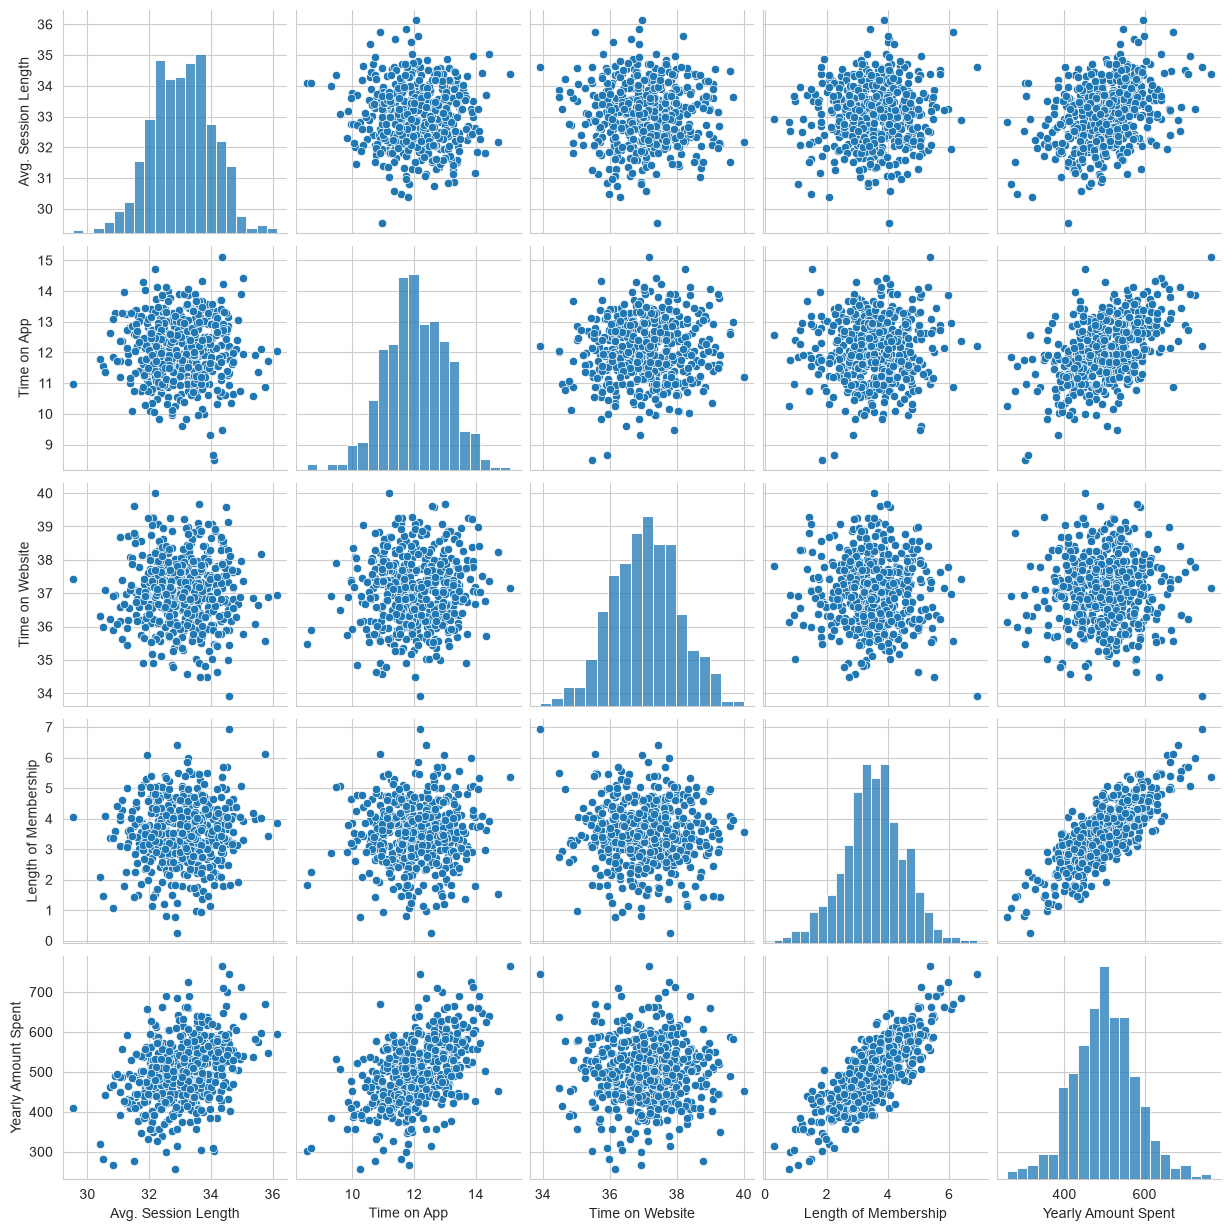

In [8]:
sns.pairplot(data=customers)

The pairplot suggests that **Length of Membership** is the feature most strongly related to yearly spend.
A linear model plot confirms an almost straight-line relationship:

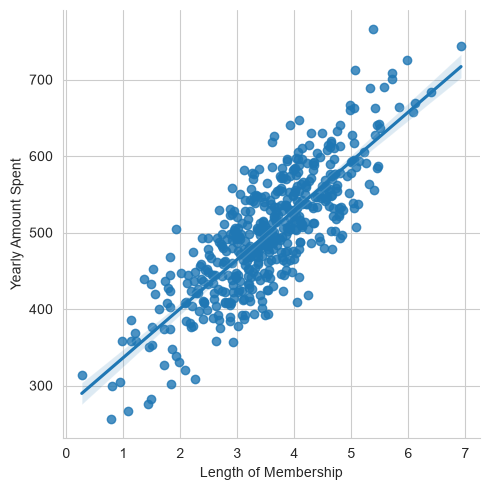

In [9]:
sns.lmplot(data=customers, x='Length of Membership', y='Yearly Amount Spent')

## 3. Train / test split

Only the four numeric behaviour features are used (email, address and avatar colour are identifiers, not predictors).

In [10]:
from sklearn.model_selection import train_test_split

X = customers[['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']]
y = customers['Yearly Amount Spent']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

## 4. Model

In [11]:
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[25.98,38.59, 0.19,61.28]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Avg. Session Length','Time on App','Time on Website', 'Length of Membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1048
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


## 5. Evaluation on the test set

Text(0, 0.5, 'Predicted yearly spend')

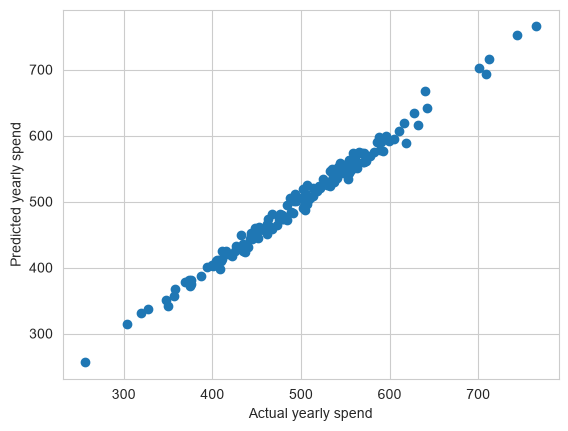

In [12]:
predictions = lm.predict(X_test)

plt.scatter(y_test, predictions)
plt.xlabel('Actual yearly spend')
plt.ylabel('Predicted yearly spend')

In [13]:
from sklearn import metrics

MAE = metrics.mean_absolute_error(y_test, predictions)
MSE = metrics.mean_squared_error(y_test, predictions)
RMSE = np.sqrt(MSE)
R2 = metrics.r2_score(y_test, predictions)

print('MAE :', round(MAE, 2))
print('MSE :', round(MSE, 2))
print('RMSE:', round(RMSE, 2))
print('R^2 :', round(R2, 4))

MAE : 7.23
MSE : 79.81
RMSE: 8.93
R^2 : 0.989


### Residuals
If the model is appropriate, residuals should be roughly normally distributed around zero.

Text(0.5, 0, 'Residual (actual - predicted)')

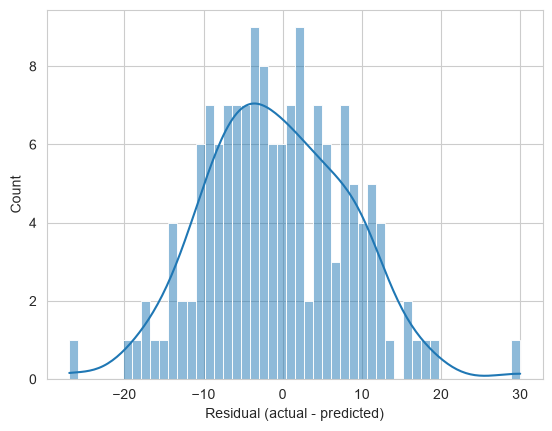

In [14]:
sns.histplot(y_test - predictions, bins=50, kde=True)
plt.xlabel('Residual (actual - predicted)')

## 6. Interpreting the coefficients

In [15]:
coefficients = pd.DataFrame(lm.coef_, X.columns, columns=['Coefficient'])
coefficients

,Coefficient
Avg. Session Length,25.981550
Time on App,38.590159
Time on Website,0.190405
Length of Membership,61.279097


Holding all other features fixed, a **one-unit increase** in:

- **Avg. Session Length** → about **\$26** more yearly spend
- **Time on App** → about **\$39** more yearly spend
- **Time on Website** → only about **\$0.19** more yearly spend
- **Length of Membership** (1 year) → about **\$61** more yearly spend

## 7. Conclusion

- The model explains almost all of the variance in yearly spend on unseen data (R² ≈ 0.99), and residuals look normally distributed, so a linear model is a good fit here.
- **Length of Membership** is by far the strongest driver: keeping customers loyal matters more than any channel.
- The **app** is clearly more productive than the **website** per minute of usage.

**Business answer:** there are two reasonable strategies:
1. Keep investing in the app, since it is already working well, **or**
2. Improve the website so it catches up with the app.

Which is better depends on costs and on *why* the website underperforms, so I would also look at how membership length interacts with app and website usage before deciding.

> Note: this is a synthetic dataset from the course, so the near-perfect fit is not typical of real customer data.